# Power-law vs log-normal bias

Compares the closure of the unbiasing for the two bias shapes (see `BIAS.md`), in both pT bins, for
$p_{\mathrm{T}}$, EEC, jet mass, $R_{\mathrm{g}}$, $k_{\mathrm{T}}$ and broadening.

For each observable there are two figures, power-law bias first, then log-normal bias, each with the two pT bins
side by side. Every panel shows the biased, reweighted and unbiased distributions, with their ratio to the unbiased one.

Inputs: the histograms saved by `plot_unbias_weights` in `../Output/files/unbias_weights_plots_<bin>[_lognormal]_<TAG>.root`,
so run the power-law chain (`driveBins.C`, `runUnbiasing.sh`, `runPlotUnbiasedWeights.sh`) and `runLognormal.sh`
with `UNBIAS_TAG=<TAG>` first. Style from `plot_mpl.py`. Run from `AnalysisCode/`.

In [1]:
import os

import numpy as np
import uproot
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import plot_mpl as pm   # shared style and helpers

pm.use_tex_if_available()

True

In [2]:
# --- EDIT ---
TAG = "1M"   # sample tag = UNBIAS_TAG of the runs to compare (e.g. 10M, 50K)
FILES_DIR = "../Output/files"
SAVE = True   # also save every figure as PDF
PLOT_DIR = f"../Output/plots/mpl/comparison/{TAG}"

BINS = [(100, 140), (140, 180)]
BIASES = {                       # name -> (file-name part, label)
    "powerlaw": ("", "Power-law bias"),
    "lognormal": ("_lognormal", "Log-normal bias"),
}

# Histogram binning per observable (the plots merge the bins saved by plot_unbias_weights):
#   int k        -> merge every k adjacent bins
#   list of edges -> custom bins; every edge must be one of the original bin edges
#   None / absent -> original binning
# Original: pt 80 bins of 0.5 GeV, eec 60 log bins in 0.004-0.4, jet_mass 30, rg 13, kt 20, broadening 25.
REBIN = {
    "pt": 4,      # 20 bins of 2 GeV
    "eec": 2,     # 30 log bins
    # "jet_mass": 2,
    # "kt": [0, 2, 4, 6, 8, 10, 14, 20, 30, 40],
}


In [3]:
# observable -> (histogram stem in the ROOT file, x label, log x, legend position)
OBSERVABLES = {
    "pt":         ("",       r"$p_{\mathrm{T}}$ [GeV]",           False, "upper right"),
    "eec":        ("_eec",   r"$\theta$",                         True,  "lower right"),
    "jet_mass":   ("_mass",  r"$M_{\mathrm{jet}}$ [GeV]",         False, "upper right"),
    "rg":         ("_rg",    r"$R_{\mathrm{g}}$",                 False, "upper right"),
    "kt":         ("_kt",    r"$k_{\mathrm{T}}$ [GeV]",           False, "upper right"),
    "broadening": ("_broad", r"$\lambda_{1}$",       False, "upper right"),
}


def rebin(h, spec):
    # merge bins of a pm.Hist: spec = merge factor (int) or list of edges (subset of h.edges)
    if spec is None:
        return h
    if isinstance(spec, int):
        starts = np.arange(0, len(h.values), spec)
        return pm.Hist(np.append(h.edges[starts], h.edges[-1]),
                       np.add.reduceat(h.values, starts),
                       np.sqrt(np.add.reduceat(h.errors ** 2, starts)))
    pos = []
    for e in spec:
        m = np.flatnonzero(np.isclose(h.edges, e, rtol=1e-9, atol=1e-12))
        if not m.size:
            raise ValueError(f"rebin: edge {e} is not one of the original bin edges")
        pos.append(int(m[0]))
    pos = np.array(pos)
    starts = pos[:-1]
    ends = pos[1:]
    csum_v = np.concatenate([[0.0], np.cumsum(h.values)])
    csum_e = np.concatenate([[0.0], np.cumsum(h.errors ** 2)])
    return pm.Hist(h.edges[pos], csum_v[ends] - csum_v[starts], np.sqrt(csum_e[ends] - csum_e[starts]))


def load(bias, lo, hi, tag=None):
    # {observable: (biased, reweighted, unbiased, y label)} from one unbias_weights_plots file
    part = BIASES[bias][0]
    path = f"{FILES_DIR}/unbias_weights_plots_{lo}_{hi}{part}_{tag or TAG}.root"
    out = {}
    with uproot.open(path) as f:
        keys = {k.split(";")[0] for k in f.keys()}
        for obs, (stem, *_rest) in OBSERVABLES.items():
            names = [f"h{stem}_{s}" for s in ("base", "total", "target")]
            if set(names) <= keys:
                hists = [rebin(pm.Hist.from_root(f[n]), REBIN.get(obs)) for n in names]
                out[obs] = (*hists, "EEC" if obs == "eec" else pm.y_title(f[names[2]]))
    return out


data = {(b, lo, hi): load(b, lo, hi) for b in BIASES for lo, hi in BINS}
print("loaded:", ", ".join(f"{b} {lo}-{hi}" for b, lo, hi in data))

loaded: powerlaw 100-140, powerlaw 140-180, lognormal 100-140, lognormal 140-180


In [4]:
def compare(obs, bias):
    # one figure for one observable and one bias type: the pT bins side by side
    _stem, xlabel, logx, legend_loc = OBSERVABLES[obs]
    fig = plt.figure(figsize=(7.6, 4.2), layout="constrained")
    cells = fig.subfigures(1, len(BINS), squeeze=False)[0]
    for c, (lo, hi) in enumerate(BINS):
        if obs not in data[(bias, lo, hi)]:
            cells[c].set_visible(False)
            continue
        hb, ht, hg, ylabel = data[(bias, lo, hi)][obs]
        a, b = cells[c].subplots(2, 1, sharex=True, height_ratios=[3, 1])
        pm.draw_ratio_plot(a, b, hb, ht, hg, xlabel, ylabel, logx=logx, logy=True,
                           target_name="", legend_loc=legend_loc if c == 0 else None,
                           label=pm.bin_label(lo, hi) + "\n" + BIASES[bias][1], bands_only=True)
    if SAVE:
        os.makedirs(PLOT_DIR, exist_ok=True)
        fig.savefig(f"{PLOT_DIR}/compare_{obs}_{bias}.pdf", bbox_inches="tight")
    plt.show()

## Jet $p_{\mathrm{T}}$

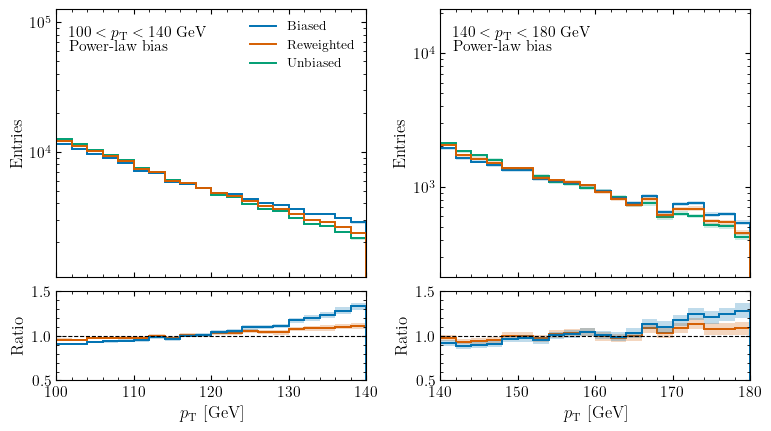

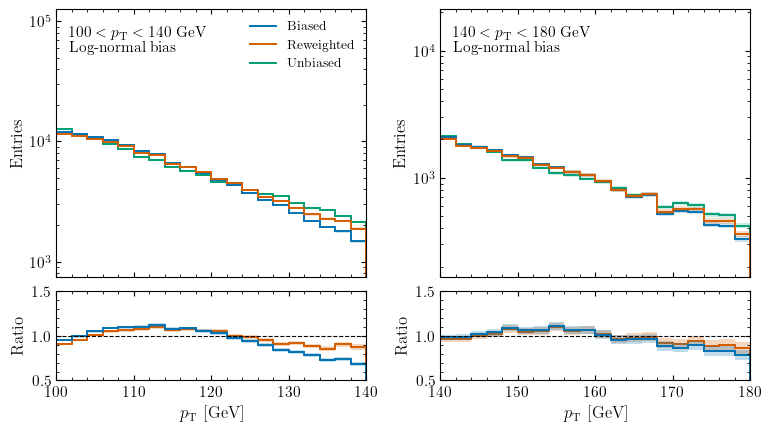

In [5]:
compare("pt", "powerlaw")
compare("pt", "lognormal")

## EEC

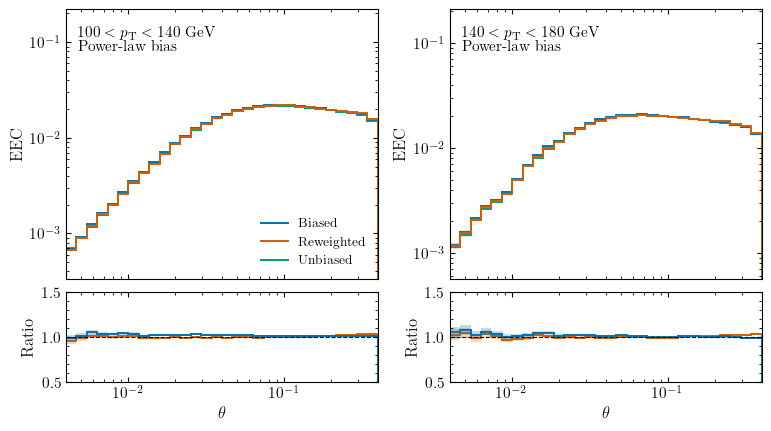

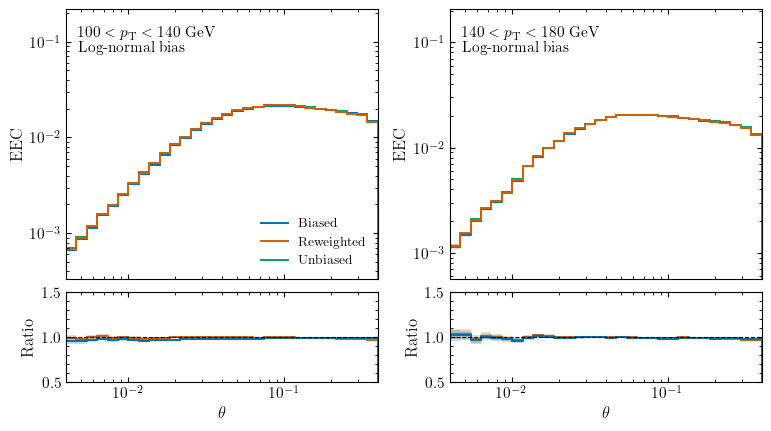

In [6]:
compare("eec", "powerlaw")
compare("eec", "lognormal")

## Jet mass

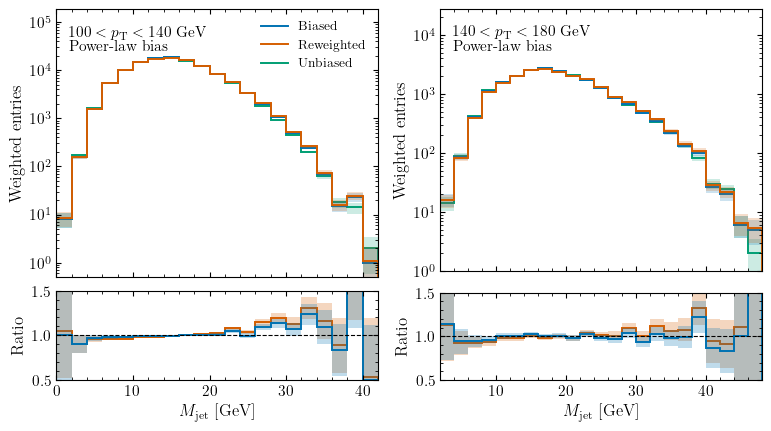

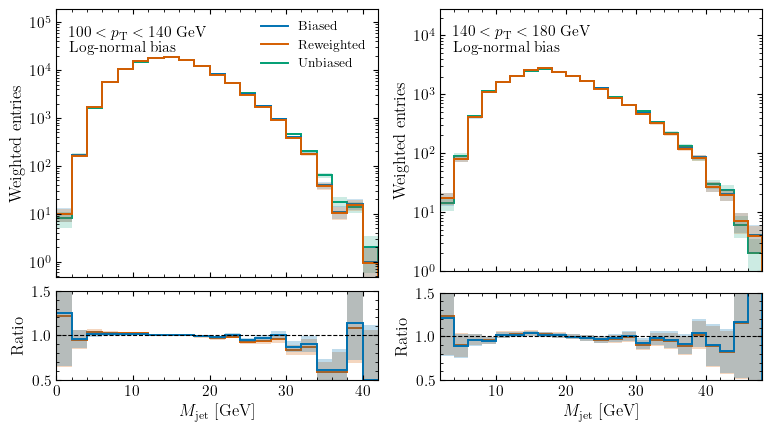

In [7]:
compare("jet_mass", "powerlaw")
compare("jet_mass", "lognormal")

## Groomed radius $R_{\mathrm{g}}$

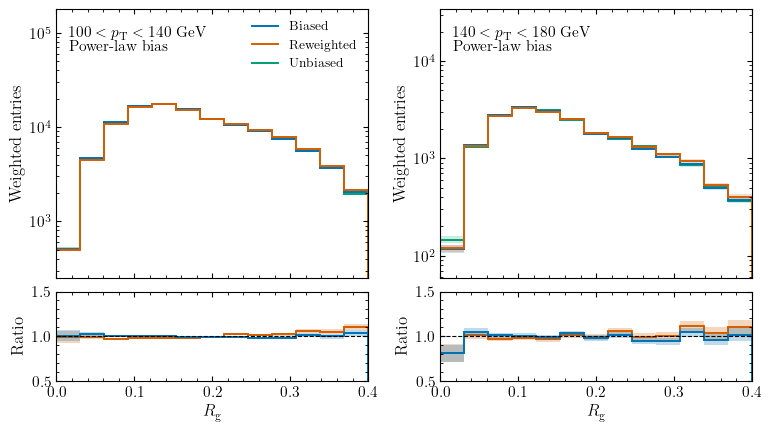

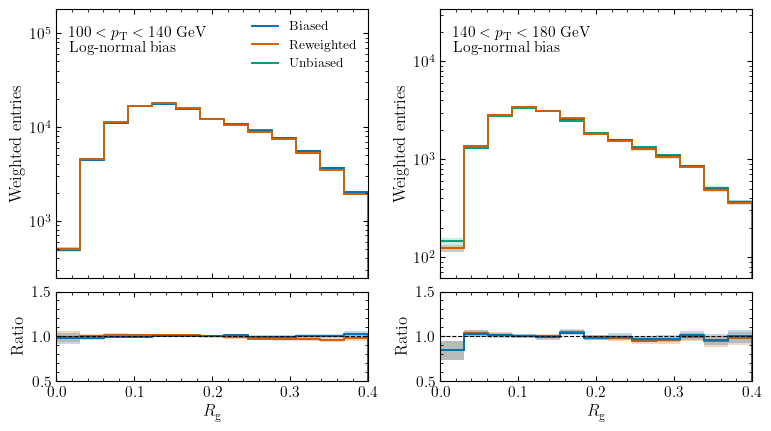

In [8]:
compare("rg", "powerlaw")
compare("rg", "lognormal")

## Groomed $k_{\mathrm{T}}$

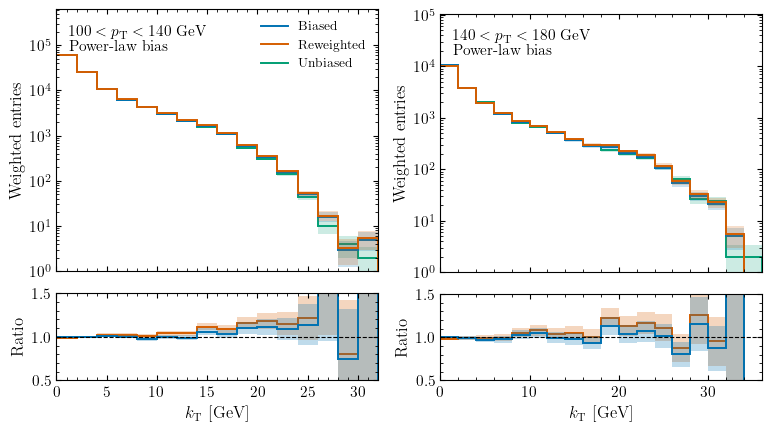

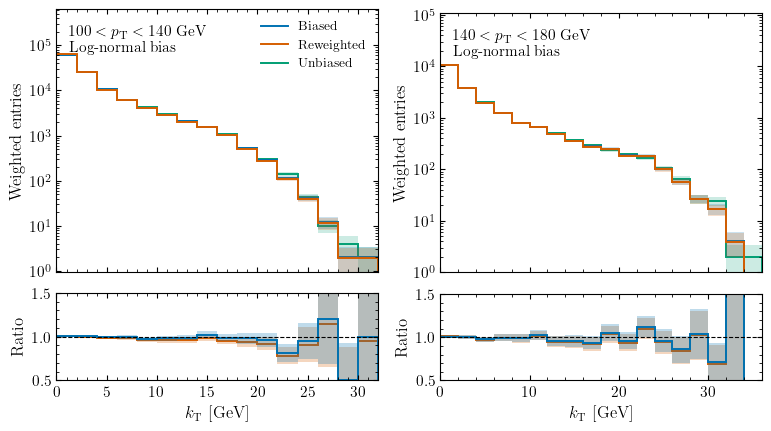

In [9]:
compare("kt", "powerlaw")
compare("kt", "lognormal")

## Broadening

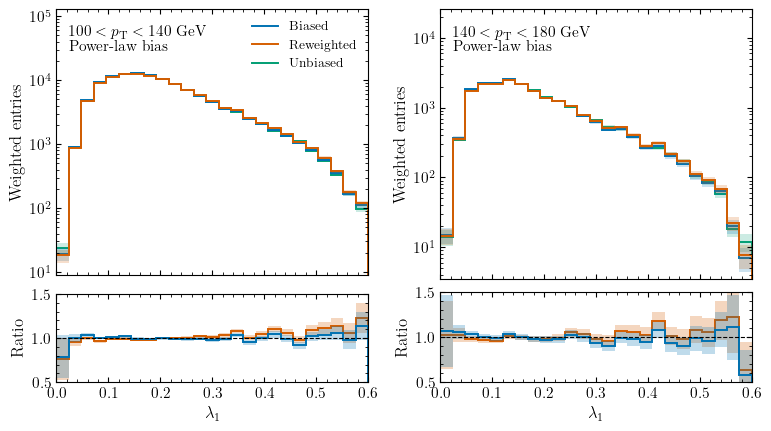

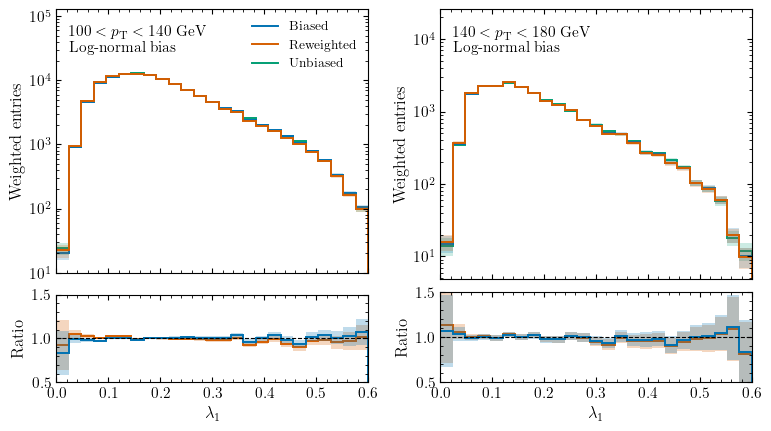

In [10]:
compare("broadening", "powerlaw")
compare("broadening", "lognormal")

## Log-normal variants

Parameters in `driveBinsLognormal.C` (or `UNBIAS_LN_SIGMA`, `UNBIAS_LN_NORM`, `UNBIAS_LN_PEAK1/2`); peak at $\exp(\mu-\sigma^2)$.

- **Default:** $\sigma = 0.12$, norm $= 1$, peak 112 / 152 GeV
- **Gentle:** $\sigma = 0.25$
- **Sharp:** $\sigma = 0.06$

One colour per variant; dashed: biased, solid: reweighted, black: unbiased. Ratio panel: divided by unbiased.

In [11]:
# variant -> (sample tag of the log-normal run, label)
VARIANTS = {
    "sharp":     (f"{TAG}_sharp",     r"$\sigma = 0.06$"),
    "default":   (TAG,                r"$\sigma = 0.12$"),
    "gentle":    (f"{TAG}_gentle",    r"$\sigma = 0.25$"),
}


def load_variants(variants):
    # {(variant, lo, hi): load(...)} for every log-normal run in variants that exists
    out = {}
    for v, (tag, _) in variants.items():
        for lo, hi in BINS:
            path = f"{FILES_DIR}/unbias_weights_plots_{lo}_{hi}_lognormal_{tag}.root"
            if os.path.exists(path):
                out[(v, lo, hi)] = load("lognormal", lo, hi, tag=tag)
            else:
                print("missing:", path)
    return out


def chi2(h, ref):
    # shape chi2/ndf of h vs ref (both normalised to unit area)
    ok = (h.values > 0) & (ref.values > 0)
    a, b = h.values[ok] / h.values[ok].sum(), ref.values[ok] / ref.values[ok].sum()
    ea, eb = h.errors[ok] / h.values[ok].sum(), ref.errors[ok] / ref.values[ok].sum()
    return float(((a - b) ** 2 / (ea ** 2 + eb ** 2)).sum() / ok.sum())


def chi2_table(vd):
    print(f"chi2/ndf vs unbiased, biased -> reweighted")
    print(f"{'variant':10} {'bin':8}" + "".join(f"{o:>14}" for o in OBSERVABLES))
    for (v, lo, hi), d in vd.items():
        row = "".join(f"{chi2(d[o][0], d[o][2]):6.1f}->{chi2(d[o][1], d[o][2]):<6.1f}" if o in d else f"{'':>14}"
                      for o in OBSERVABLES)
        print(f"{v:10} {lo}-{hi:<4} {row}")


vdata = load_variants(VARIANTS)
chi2_table(vdata)


chi2/ndf vs unbiased, biased -> reweighted
variant    bin                 pt           eec      jet_mass            rg            kt    broadening
sharp      100-140    86.1->57.0     2.7->15.4     1.3->2.7      0.4->2.4      0.5->1.5      0.6->1.3   
sharp      140-180    12.8->7.1      0.8->6.8      0.5->0.8      0.7->1.4      0.4->0.6      0.3->0.5   
default    100-140    38.2->14.5     2.3->14.0     1.1->2.4      0.3->1.8      0.5->1.5      0.6->1.2   
default    140-180     3.2->1.8      1.1->3.3      0.5->0.6      0.5->0.8      0.4->0.5      0.2->0.3   
gentle     100-140     5.5->2.1      0.7->3.8      0.4->0.8      0.3->0.7      0.2->0.5      0.5->0.7   
gentle     140-180     0.6->0.6      0.9->1.1      0.3->0.3      0.5->0.5      0.3->0.3      0.2->0.2   


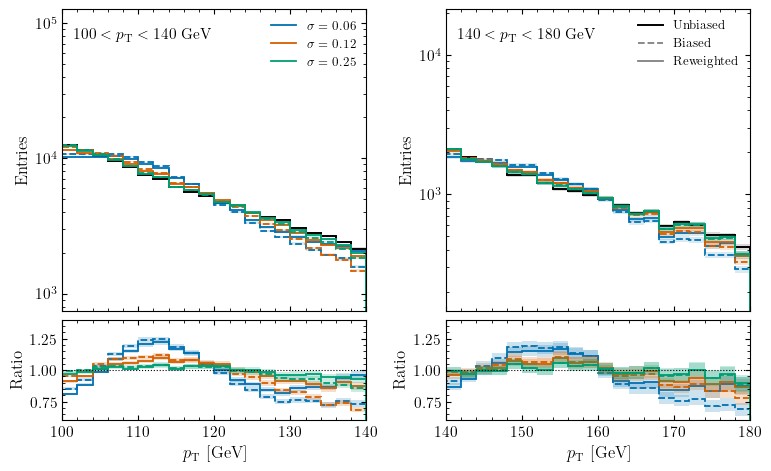

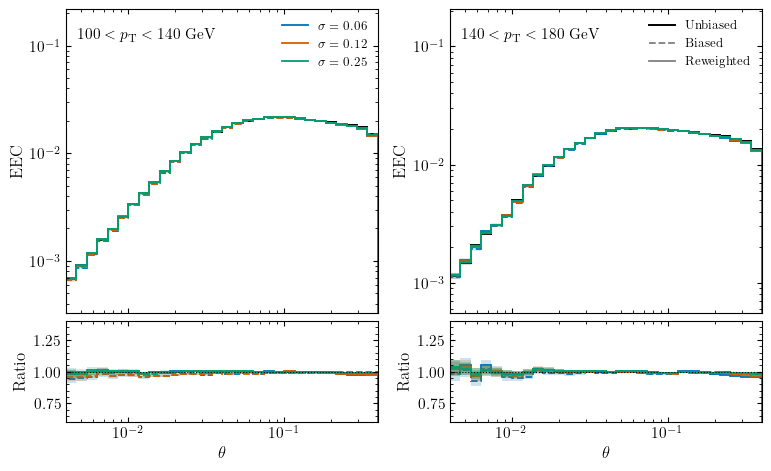

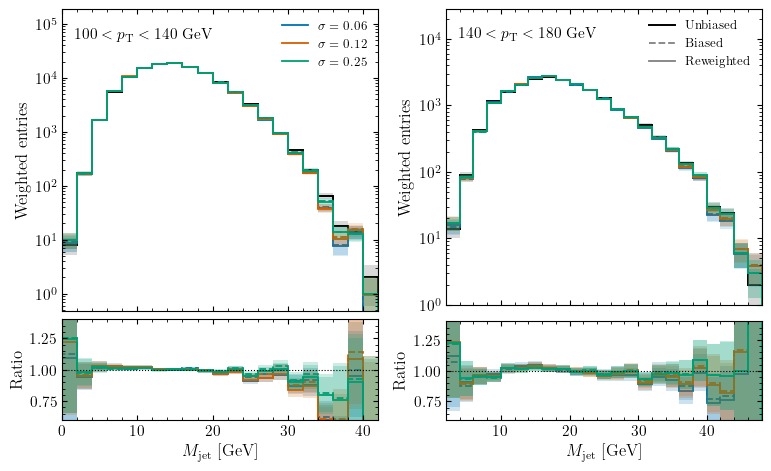

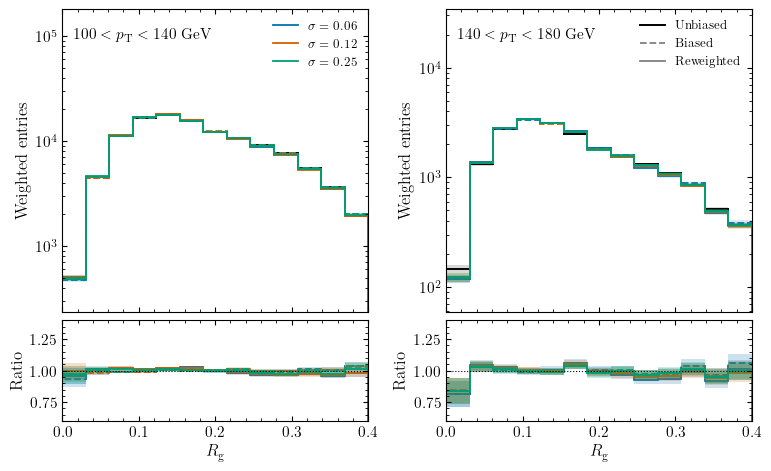

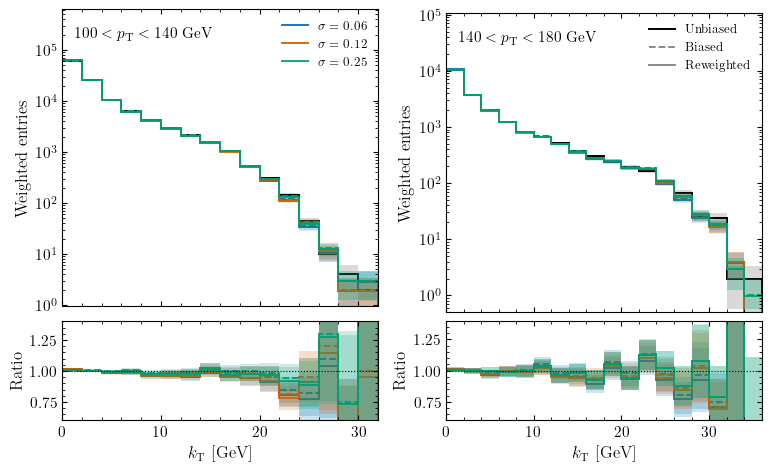

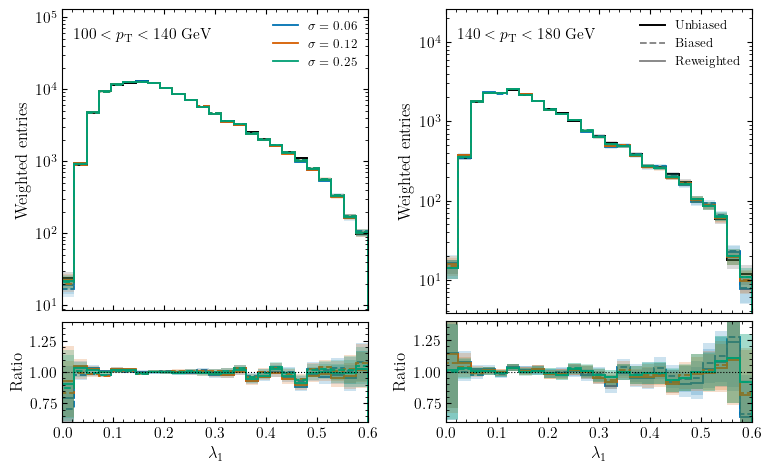

In [12]:
OBS_NAME = {"pt": r"$p_{\mathrm{T}}$", "eec": "EEC", "jet_mass": r"$M_{\mathrm{jet}}$",
            "rg": r"$R_{\mathrm{g}}$", "kt": r"$k_{\mathrm{T}}$", "broadening": r"$\lambda_{1}$"}


def compare_variants(obs, variants=None, vd=None, name="lognormal_variants"):
    # as compare(), with one colour per log-normal variant: biased dashed, reweighted solid;
    # unbiased (the same reference sample for every variant) in black
    variants = VARIANTS if variants is None else variants
    vd = vdata if vd is None else vd
    colors = dict(zip(variants, pm.OKABE_ITO))
    _stem, xlabel, logx, _ = OBSERVABLES[obs]
    fig = plt.figure(figsize=(7.6, 4.6), layout="constrained")
    cells = fig.subfigures(1, len(BINS), squeeze=False)[0]
    for c, (lo, hi) in enumerate(BINS):
        present = [v for v in variants if (v, lo, hi) in vd and obs in vd[(v, lo, hi)]]
        if not present:
            cells[c].set_visible(False)
            continue
        a, b = cells[c].subplots(2, 1, sharex=True, height_ratios=[3, 1])
        hg, ylabel = vd[(present[0], lo, hi)][obs][2], vd[(present[0], lo, hi)][obs][3]
        pm.draw_band(a, hg, "black", alpha=0.15)
        a.stairs(hg.values, hg.edges, color="black", lw=1.4)
        shown = [hg]
        for v in present:
            hb, ht, hg_v, _ = vd[(v, lo, hi)][obs]
            for h, ls in ((hb, "--"), (ht, "-")):
                pm.draw_band(a, h, colors[v], alpha=0.15)
                a.stairs(h.values, h.edges, color=colors[v], lw=1.3, ls=ls)
                r = h.divide(hg_v)
                pm.draw_band(b, r, colors[v], alpha=0.2)
                b.stairs(r.values, r.edges, color=colors[v], lw=1.3, ls=ls)
            shown += [hb, ht]
        a.set_yscale("log")
        vals = np.concatenate([h.values for h in shown])
        pos = vals[np.isfinite(vals) & (vals > 0)]
        if pos.size:
            a.set_ylim(0.5 * pos.min(), 10 * pos.max())
        a.set_ylabel(ylabel)
        a.text(0.04, 0.94, pm.bin_label(lo, hi), transform=a.transAxes, va="top")
        if logx:
            b.set_xscale("log")
            b.xaxis.set_minor_formatter(plt.NullFormatter())
        b.axhline(1.0, color="black", ls=":", lw=0.8)
        b.set_ylim(0.6, 1.4)
        b.set_xlim(*pm.data_xlim(shown))
        b.set_xlabel(xlabel)
        b.set_ylabel("Ratio")
        # legends: variants (left bin), line styles (right bin)
        if c == 0:
            a.legend([Line2D([], [], color=colors[v], lw=1.3) for v in variants],
                     [variants[v][1] for v in variants], loc="upper right", fontsize="small")
        if c == len(BINS) - 1:
            a.legend([Line2D([], [], color="black", lw=1.4), Line2D([], [], color="gray", lw=1.3, ls="--"),
                      Line2D([], [], color="gray", lw=1.3)],
                     ["Unbiased", "Biased", "Reweighted"], loc="upper right", fontsize="small")
    if SAVE:
        os.makedirs(PLOT_DIR, exist_ok=True)
        fig.savefig(f"{PLOT_DIR}/{name}_{obs}.pdf", bbox_inches="tight")
    plt.show()


for obs in OBSERVABLES:
    compare_variants(obs)
